# Sieci neuronowe i deep learning - Lab 2

## Neuron, MLP i backpropagation

W tym laboratorium najpierw implementujemy propagację w przód i wstecz ręcznie w NumPy, a potem porównujemy ten sam schemat z automatycznym różniczkowaniem w PyTorch.

Używamy małego dwuwymiarowego problemu klasyfikacji, żeby można było oglądać granicę decyzyjną modelu.

## Ćwiczenie 1

- Wygeneruj dwuwymiarowy zbiór danych do klasyfikacji binarnej.
- Podziel dane na zbiory treningowy, walidacyjny i testowy.
- Przeskaluj cechy, dopasowując skaler wyłącznie na zbiorze treningowym.
- Wyświetl dane treningowe na wykresie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# TODO: wygeneruj dane funkcją make_moons.
# TODO: wykonaj podział train/validation/test z zachowaniem proporcji klas.
# TODO: dopasuj StandardScaler tylko na zbiorze treningowym.

X, y = make_moons(n_samples=1000, noise=0.2, random_state=RANDOM_STATE)

# 60% train, 20% validation, 20% test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("train:", X_train.shape)
print("validation:", X_val.shape)
print("test:", X_test.shape)

train: (600, 2)
validation: (200, 2)
test: (200, 2)


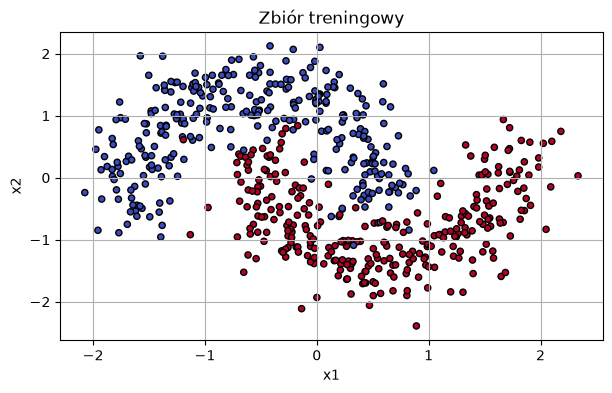

In [3]:
# TODO: narysuj zbiór treningowy na wykresie punktowym.
# Użyj X_train[:, 0], X_train[:, 1] oraz koloru zależnego od y_train.

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolors="k", s=20)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Zbiór treningowy")
plt.show()

## Ćwiczenie 2

- Zaimplementuj funkcję sigmoidalną i binary crossentropy.
- Wytrenuj pojedynczy neuron logistyczny z użyciem gradient descent.
- Narysuj przebieg funkcji straty i granicę decyzyjną.

Dla neuronu logistycznego:

`z = XW + b`

`a = sigmoid(z)`

`dZ = (a - y) / m`

`dW = X.T @ dZ`

`db = sum(dZ)`

In [4]:
def sigmoid(z):
    # TODO: zaimplementuj sigmoid
    return 1 / (1 + np.exp(-z))


def binary_crossentropy(y_true, y_score, eps=1e-7):
    # TODO: zaimplementuj binary crossentropy
    y_true = np.ravel(y_true)
    y_score = np.clip(np.ravel(y_score), eps, 1 - eps)
    return -np.mean(y_true * np.log(y_score) + (1 - y_true) * np.log(1 - y_score))


def accuracy_from_scores(y_true, y_score, threshold=0.5):
    # TODO: zamień score na klasy i policz accuracy_score
    y_pred = (np.ravel(y_score) >= threshold).astype(int)
    return accuracy_score(np.ravel(y_true), y_pred)


def plot_loss(losses, title):
    # TODO: narysuj przebieg funkcji straty
    plt.plot(losses)
    plt.xlabel("epoka")
    plt.ylabel("binary crossentropy")
    plt.title(title)
    plt.show()


def plot_decision_boundary(predict_scores, X_data, y_data, title, ax=None):
    # TODO: utwórz siatkę punktów, policz score modelu i narysuj granicę decyzyjną
    x_min, x_max = X_data[:, 0].min() - 0.5, X_data[:, 0].max() + 0.5
    y_min, y_max = X_data[:, 1].min() - 0.5, X_data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = np.asarray(predict_scores(grid)).reshape(xx.shape)

    show = ax is None
    if ax is None:
        _, ax = plt.subplots()

    ax.contourf(xx, yy, scores, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.5)
    ax.contour(xx, yy, scores, levels=[0.5], colors="k")
    ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap="coolwarm", edgecolors="k", s=20)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)

    if show:
        plt.show()

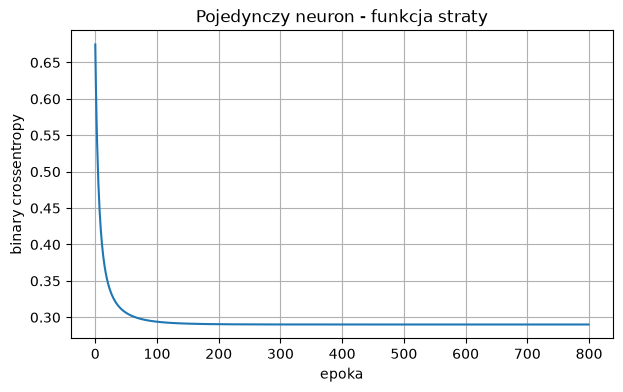

train accuracy: 0.8683333333333333
validation accuracy: 0.825


In [5]:
m, n_features = X_train.shape
y_train_col = y_train.reshape(-1, 1)

W = np.random.normal(0, 0.1, size=(n_features, 1))
b = np.zeros((1,))

learning_rate = 0.3
epochs = 800
losses = []

for epoch in range(epochs):
    # TODO: forward pass: z, y_score, loss
    z = X_train @ W + b
    y_score = sigmoid(z)
    loss = binary_crossentropy(y_train_col, y_score)
    losses.append(loss)

    # TODO: backward pass: dz, dW, db
    dz = (y_score - y_train_col) / m
    dW = X_train.T @ dz
    db = np.sum(dz, axis=0)

    # TODO: aktualizacja W i b
    W -= learning_rate * dW
    b -= learning_rate * db

# TODO: narysuj funkcję straty i policz accuracy train/validation
plot_loss(losses, "Pojedynczy neuron - funkcja straty")


def neuron_scores(X_data):
    return sigmoid(X_data @ W + b)


print("train accuracy:", accuracy_from_scores(y_train, neuron_scores(X_train)))
print("validation accuracy:", accuracy_from_scores(y_val, neuron_scores(X_val)))

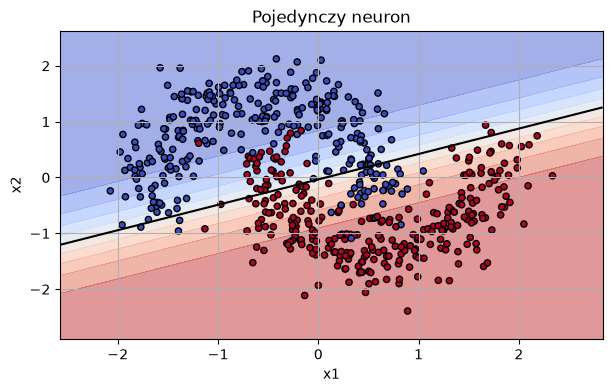

In [6]:
# TODO: narysuj granicę decyzyjną pojedynczego neuronu.
plot_decision_boundary(neuron_scores, X_train, y_train, "Pojedynczy neuron")

## Ćwiczenie 3

- Zaimplementuj dwuwarstwowy MLP w NumPy.
- W funkcji `mlp_forward` zapisz wartości potrzebne później w propagacji wstecznej.
- W funkcji `mlp_backward` policz gradienty dla `W1`, `b1`, `W2`, `b2`.
- Sprawdź jeden gradient metodą różnic skończonych.

In [7]:
hidden_dim = 8
m, n_features = X_train.shape
y_train_col = y_train.reshape(-1, 1)

params = {
    "W1": np.random.normal(0, 1 / np.sqrt(n_features), size=(n_features, hidden_dim)),  # TODO
    "b1": np.zeros((1, hidden_dim)),  # TODO
    "W2": np.random.normal(0, 1 / np.sqrt(hidden_dim), size=(hidden_dim, 1)),  # TODO
    "b2": np.zeros((1, 1)),  # TODO
}

In [8]:
def mlp_forward(X_batch, params):
    # TODO: Z1, A1, Z2, A2
    Z1 = X_batch @ params["W1"] + params["b1"]
    A1 = np.tanh(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = sigmoid(Z2)

    # TODO: zapisz cache potrzebny do backpropagation
    cache = {"X": X_batch, "A1": A1, "A2": A2}
    return A2, cache


def mlp_backward(y_true, params, cache):
    m = y_true.shape[0]

    # TODO: policz dZ2, dW2, db2
    dZ2 = (cache["A2"] - y_true) / m
    dW2 = cache["A1"].T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # TODO: policz dA1, dZ1, dW1, db1
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (1 - cache["A1"] ** 2)
    dW1 = cache["X"].T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


def update_params(params, grads, learning_rate):
    # TODO: wykonaj krok gradient descent dla każdego parametru
    for name in params:
        params[name] -= learning_rate * grads[name]

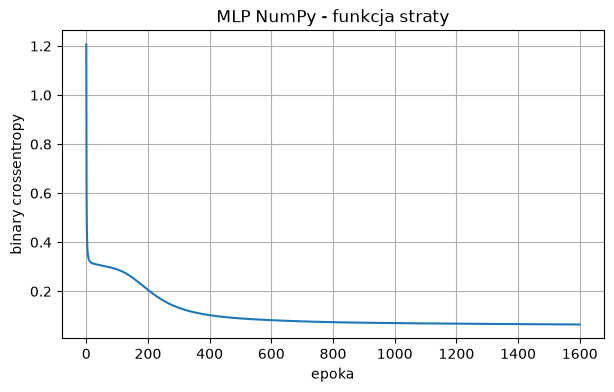

train accuracy: 0.9783333333333334
validation accuracy: 0.95


In [9]:
learning_rate = 0.8
epochs = 1600
losses = []

for epoch in range(epochs):
    # TODO: forward, loss, backward, update
    y_score, cache = mlp_forward(X_train, params)
    loss = binary_crossentropy(y_train_col, y_score)
    losses.append(loss)

    grads = mlp_backward(y_train_col, params, cache)
    update_params(params, grads, learning_rate)

# TODO: narysuj stratę i policz accuracy train/validation
plot_loss(losses, "MLP NumPy - funkcja straty")


def mlp_scores(X_data):
    return mlp_forward(X_data, params)[0]


mlp_val_acc = accuracy_from_scores(y_val, mlp_scores(X_val))
print("train accuracy:", accuracy_from_scores(y_train, mlp_scores(X_train)))
print("validation accuracy:", mlp_val_acc)

In [10]:
# TODO: sprawdź jeden wybrany gradient metodą różnic skończonych.
# Porównaj gradient analityczny z numerycznym.

_, cache = mlp_forward(X_train, params)
grads = mlp_backward(y_train_col, params, cache)

name, idx = "W1", (0, 0)
eps = 1e-5
original = params[name][idx]

params[name][idx] = original + eps
loss_plus = binary_crossentropy(y_train_col, mlp_forward(X_train, params)[0])
params[name][idx] = original - eps
loss_minus = binary_crossentropy(y_train_col, mlp_forward(X_train, params)[0])
params[name][idx] = original

numeric_grad = (loss_plus - loss_minus) / (2 * eps)
analytic_grad = grads[name][idx]
relative_error = abs(analytic_grad - numeric_grad) / (abs(analytic_grad) + abs(numeric_grad))

print(f"gradient analityczny: {analytic_grad:.10f}")
print(f"gradient numeryczny:  {numeric_grad:.10f}")
print(f"błąd względny:        {relative_error:.2e}")

gradient analityczny: -0.0002211708
gradient numeryczny:  -0.0002211708
błąd względny:        2.58e-09


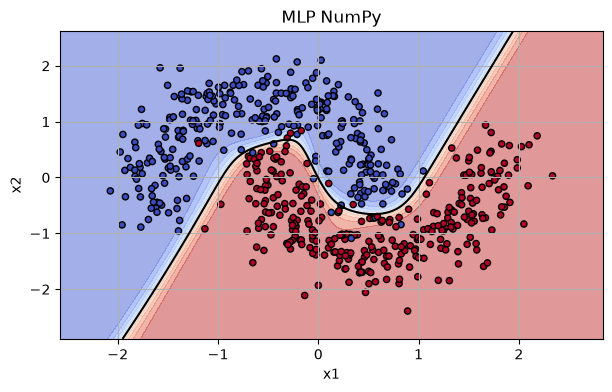

In [11]:
# TODO: narysuj granicę decyzyjną MLP zaimplementowanego w NumPy.
plot_decision_boundary(mlp_scores, X_train, y_train, "MLP NumPy")

## Cwiczenie 4

- Zbuduj podobny nieliniowy model w PyTorch.
- Uzyj recznej petli treningowej z `loss.backward()` i `optimizer.step()`.
- Uzyj stabilnego optymalizatora i sprawdz, czy granica decyzyjna rzeczywiscie jest nieliniowa.
- Wyswietl normy gradientow i porownaj wynik z implementacja NumPy.


In [12]:
import torch
from torch import nn

torch.manual_seed(RANDOM_STATE)

torch_model = nn.Sequential(
    # TODO: nn.Linear(2, 16)
    nn.Linear(2, 16),
    # TODO: nn.Tanh()
    nn.Tanh(),
    # TODO: nn.Linear(16, 1), bez sigmoidu na koncu
    nn.Linear(16, 1),
)

loss_fn = nn.BCEWithLogitsLoss()  # TODO: nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.03)  # TODO: Adam z learning_rate okolo 0.03

torch_model

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=1, bias=True)
)

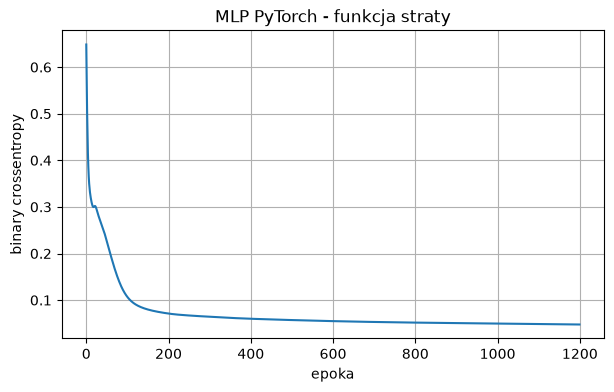

0.weight   norma gradientu: 0.000497
0.bias     norma gradientu: 0.000108
2.weight   norma gradientu: 0.000737
2.bias     norma gradientu: 0.000053


In [13]:
X_train_torch = torch.tensor(X_train, dtype=torch.float32)
y_train_torch = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)

torch_losses = []
torch_model.train()

for epoch in range(1200):
    # TODO: optimizer.zero_grad()
    optimizer.zero_grad()
    # TODO: logits = torch_model(...)
    logits = torch_model(X_train_torch)
    # TODO: loss = loss_fn(...)
    loss = loss_fn(logits, y_train_torch)
    # TODO: loss.backward()
    loss.backward()
    # TODO: optimizer.step()
    optimizer.step()

    torch_losses.append(loss.item())

# TODO: narysuj loss i wyswietl normy gradientow
plot_loss(torch_losses, "MLP PyTorch - funkcja straty")

for name, param in torch_model.named_parameters():
    print(f"{name:10s} norma gradientu: {param.grad.norm().item():.6f}")

validation accuracy PyTorch: 0.96
validation accuracy NumPy:   0.95


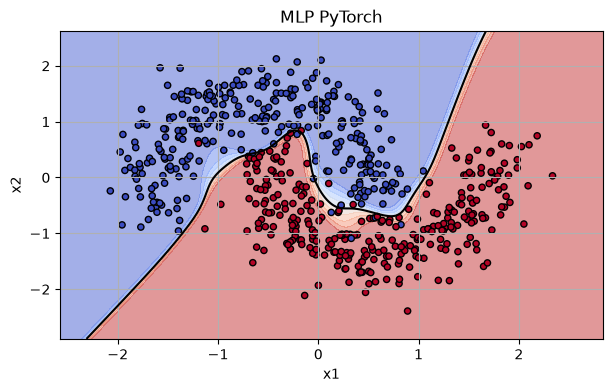

In [14]:
def predict_torch_scores(model, X_array):
    # TODO: przełącz model w tryb eval, policz logity bez gradientów,
    # a następnie zamień je na prawdopodobieństwa przez sigmoid.
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_array, dtype=torch.float32))
    return torch.sigmoid(logits).numpy()


def torch_scores(X_data):
    return predict_torch_scores(torch_model, X_data)


# TODO: policz accuracy walidacyjne i narysuj granicę decyzyjną PyTorch.
torch_val_acc = accuracy_from_scores(y_val, torch_scores(X_val))
print("validation accuracy PyTorch:", torch_val_acc)
print("validation accuracy NumPy:  ", mlp_val_acc)

plot_decision_boundary(torch_scores, X_train, y_train, "MLP PyTorch")

## Cwiczenie 5

- Uzyj zbioru testowego dopiero po obejrzeniu wynikow walidacyjnych.
- Porownaj obok siebie granice decyzyjne trzech modeli: pojedynczego neuronu, MLP NumPy i modelu PyTorch.
- Sprawdz, czy model frameworkowy nauczyl sie nieliniowej granicy, a nie tylko wersji podobnej do perceptronu.


test accuracy PyTorch: 0.985


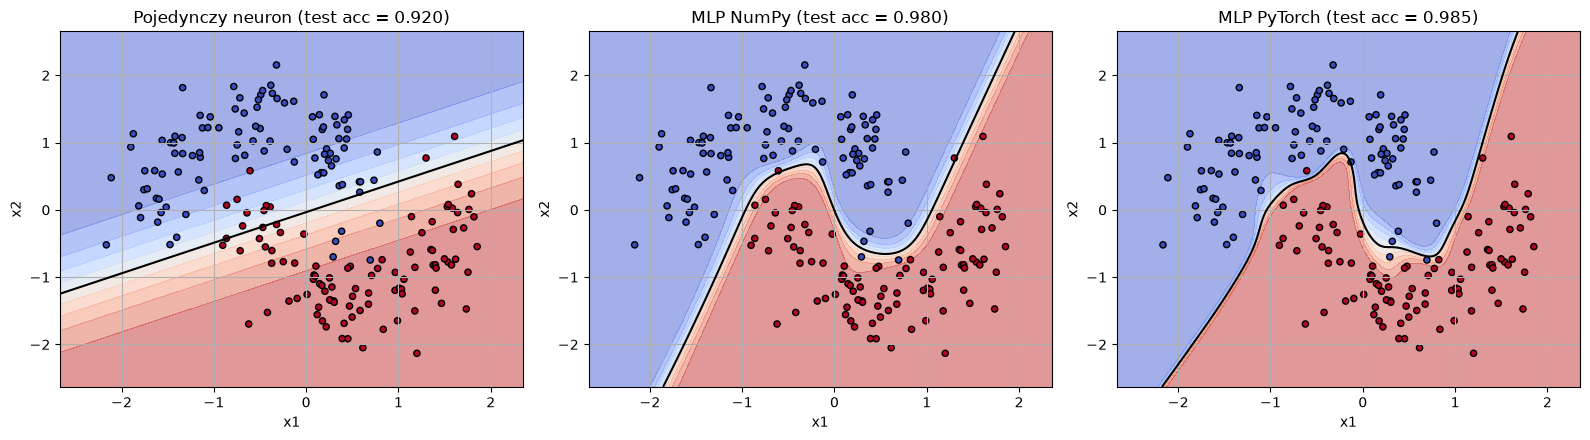

In [15]:
# TODO: policz koncowe accuracy na zbiorze testowym dla modelu PyTorch.
torch_test_acc = accuracy_from_scores(y_test, torch_scores(X_test))
print("test accuracy PyTorch:", torch_test_acc)

# TODO: narysuj w jednym rzedzie trzy granice decyzyjne:
# 1. pojedynczy neuron,
# 2. MLP NumPy,
# 3. MLP PyTorch.
#
# Podpowiedz: mozesz napisac wariant plot_decision_boundary przyjmujacy ax,
# albo uzyc trzy razy istniejacej funkcji plot_decision_boundary.

models = [
    ("Pojedynczy neuron", neuron_scores),
    ("MLP NumPy", mlp_scores),
    ("MLP PyTorch", torch_scores),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (title, predict) in zip(axes, models):
    test_acc = accuracy_from_scores(y_test, predict(X_test))
    plot_decision_boundary(predict, X_test, y_test, f"{title} (test acc = {test_acc:.3f})", ax=ax)
plt.tight_layout()
plt.show()